In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/bank-full.csv', sep=';')

df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSubscription Count:")
print(df['y'].value_counts())


Dataset Shape: (45211, 17)

Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Subscription Count:
y
no     39922
yes     5289
Name: count, dtype: int64


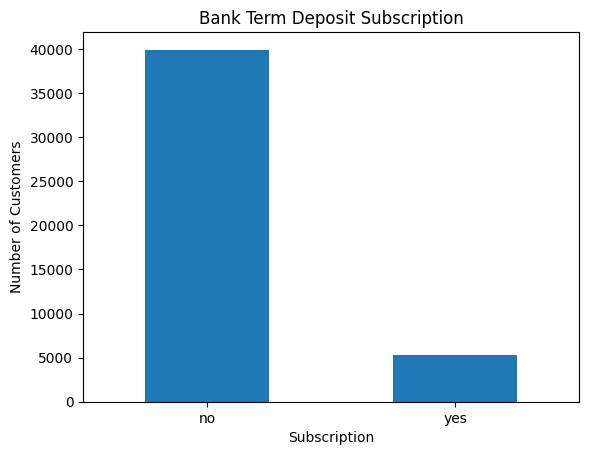

In [3]:

df['y'].value_counts().plot(kind='bar')

plt.title('Bank Term Deposit Subscription')
plt.xlabel('Subscription')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()


In [4]:

df = pd.get_dummies(df, drop_first=True)

X = df.drop('y_yes', axis=1)
y = df['y_yes']

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)


Input Shape: (45211, 42)
Output Shape: (45211,)


In [5]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (36168, 42)
Testing Data: (9043, 42)


In [6]:

from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=5, random_state=42)

model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")


Decision Tree Model Trained Successfully!


In [7]:

y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])


Predictions:
[False False False False False False False  True False False]


In [8]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 89.83744332632976 %


In [9]:

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

       False       0.91      0.98      0.94      7985
        True       0.64      0.30      0.41      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.64      0.68      9043
weighted avg       0.88      0.90      0.88      9043



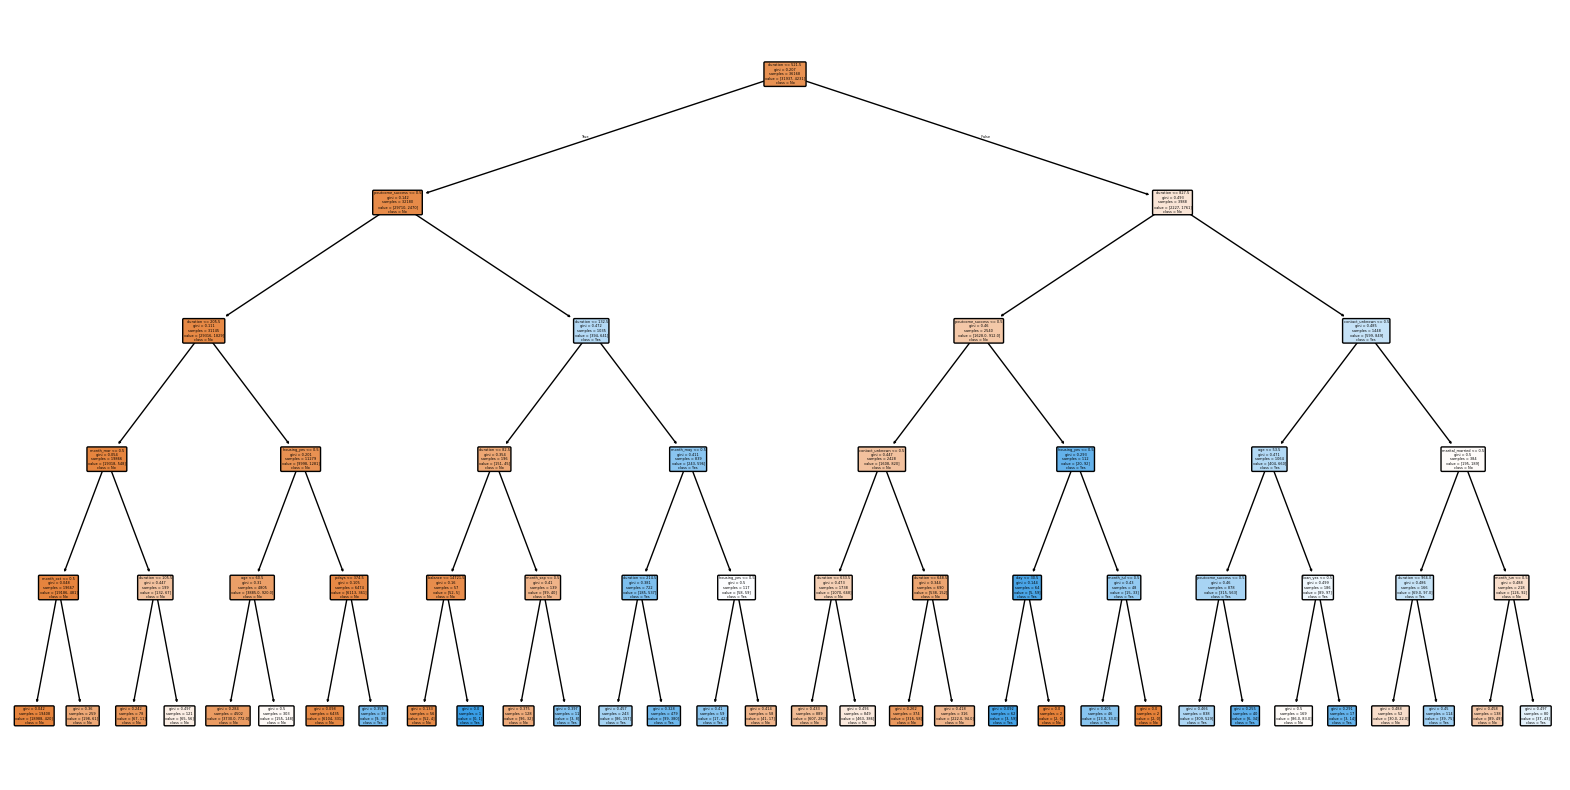

In [10]:

from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(model, filled=True, feature_names=X.columns,
          class_names=['No', 'Yes'], rounded=True)

plt.show()


## **Results and Observations**

1. The Bank Marketing dataset contains 45,211 records and 17 columns.
2. Data preprocessing converted categorical values into numerical values.
3. The dataset was divided into 80% training data and 20% testing data.
4. The Decision Tree Classifier achieved an accuracy of approximately **89.84%**.
5. The model successfully predicted whether customers would subscribe to a bank term deposit.
6. The model performed better at identifying customers who would not subscribe than those who would subscribe.

## **Conclusion**

The Decision Tree Classifier was successfully developed to predict customer subscriptions for bank term deposits. The model achieved 89.84% accuracy. The classification report helped evaluate the model's performance using precision, recall and F1-score. This project demonstrates how machine learning can help banks understand customer behaviour and predict potential subscribers.